=== データのダウンロードを開始します ===
[clock] は既に存在します。
[cat] は既に存在します。
[apple] は既に存在します。
[cake] は既に存在します。
[boomerang] は既に存在します。
=== すべてのダウンロードが完了しました ===

=== 各カテゴリの最初の1枚を描画します ===
clock のデータ数: 120536 枚
cat のデータ数: 123202 枚
apple のデータ数: 144722 枚
cake のデータ数: 124905 枚
boomerang のデータ数: 142682 枚


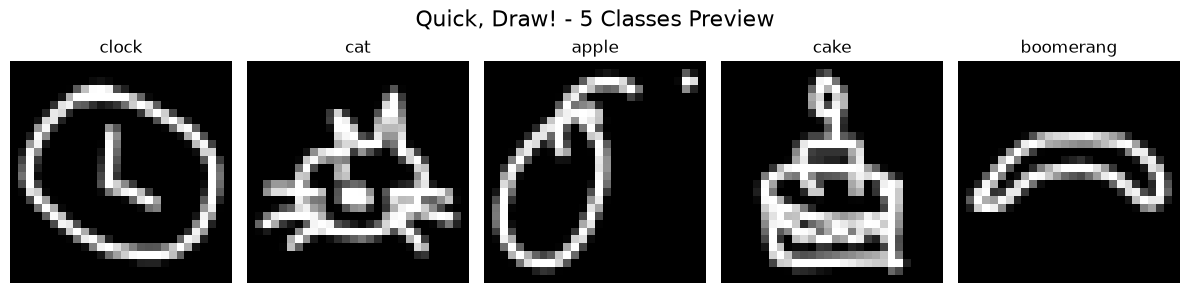

In [ ]:
# 学習データのダウンロード(Quick, Draw!)

import urllib.request
import os
import numpy as np
import matplotlib.pyplot as plt

# 1. 指定した5つのお題
classes = ["clock", "cat", "apple", "cake", "boomerang"]

base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"
os.makedirs("data", exist_ok=True)

print("=== データのダウンロードを開始します ===")
for c in classes:
    url = base_url + c + ".npy"
    file_path = f"data/{c}.npy"
    
    if not os.path.exists(file_path):
        print(f"[{c}] をダウンロード中...")
        urllib.request.urlretrieve(url.replace(" ", "%20"), file_path)
        print(f"[{c}] 完了！")
    else:
        print(f"[{c}] は既に存在します。")

print("=== すべてのダウンロードが完了しました ===\n")

# 2. データの読み込みと可視化
print("=== 各カテゴリの最初の1枚を描画します ===")

# 1行5列の描画エリアを作成
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
fig.suptitle("Quick, Draw! - 5 Classes Preview", fontsize=16)

# 各カテゴリのデータを読み込んで最初の1枚を表示
for i, c in enumerate(classes):
    # データをロード
    data = np.load(f"data/{c}.npy")
    
    # 枚数を確認（コンソールに出力）
    print(f"{c} のデータ数: {data.shape[0]} 枚")
    
    # 最初の1枚（0番目）を 28x28 に変換して画像化
    img = data[0].reshape(28, 28)
    
    # 描画
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(c)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# CNNを利用して学習するプログラム

import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# ==========================================
# 1. 設定とデータの準備
# ==========================================
classes = ["clock", "cat", "apple", "cake", "boomerang"]
num_classes = len(classes)
max_items_per_class = 20000 # 学習を早く終わらせるため、各カテゴリ2万枚に制限

print("=== データの読み込みと前処理 ===")
X = []
Y = []

for i, c in enumerate(classes):
    data = np.load(f"data/{c}.npy")
    data = data[:max_items_per_class] # 最初の2万枚だけ取得
    X.append(data)
    # ラベル（0, 1, 2, 3, 4）を作成
    labels = np.full(data.shape[0], i)
    Y.append(labels)

# データを結合
X = np.concatenate(X)
Y = np.concatenate(Y)

# CNNに入力できる形に変換
# 1. 0〜255の数値を 0.0〜1.0 に正規化
X = X.astype('float32') / 255.0
# 2. (全体の枚数, 1チャンネル, 縦28, 横28) の形に変形
X = X.reshape(-1, 1, 28, 28)

# 学習用(80%)とテスト用(20%)に分割
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# PyTorchのTensor（テンソル）形式に変換
X_train_t = torch.tensor(X_train)
Y_train_t = torch.tensor(Y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test)
Y_test_t = torch.tensor(Y_test, dtype=torch.long)

# DataLoaderの作成（データを少しずつAIに渡すための仕組み）
batch_size = 128
train_dataset = TensorDataset(X_train_t, Y_train_t)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_dataset = TensorDataset(X_test_t, Y_test_t)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# ==========================================
# 2. CNNモデルの定義
# ==========================================
class QuickDrawCNN(nn.Module):
    def __init__(self):
        super(QuickDrawCNN, self).__init__()
        # 画像の特徴を抽出する部分（畳み込み層）
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 画像サイズを半分に（28x28 -> 14x14）
            
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 画像サイズを半分に（14x14 -> 7x7）
        )
        # 抽出した特徴から答えを推論する部分（全結合層）
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes) # 最終的に5つのカテゴリに分類
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

# ==========================================
# 3. 学習の実行
# ==========================================
# M2 Macの強力なGPU(mps)を使えるかチェック
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"=== 使用するデバイス: {device} ===")

model = QuickDrawCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5 # 学習を繰り返す回数

print("=== 学習開始 ===")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad() # 勾配をリセット
        outputs = model(images) # 予測
        loss = criterion(outputs, labels) # 誤差を計算
        loss.backward() # 誤差を逆伝播
        optimizer.step() # AIのパラメータを更新
        
        running_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# ==========================================
# 4. 精度のテストとモデルの保存
# ==========================================
print("=== テストデータで精度を検証 ===")
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"正解率 (Accuracy): {100 * correct / total:.2f}%")

# 学習した脳みそをファイルとして保存
torch.save(model.state_dict(), "quickdraw_cnn.pth")
print("モデルを quickdraw_cnn.pth に保存しました！")

=== データの読み込みと前処理 ===
=== 使用するデバイス: mps ===
=== 学習開始 ===
Epoch 1/5, Loss: 0.3184
Epoch 2/5, Loss: 0.1645
Epoch 3/5, Loss: 0.1341
Epoch 4/5, Loss: 0.1150
Epoch 5/5, Loss: 0.1008
=== テストデータで精度を検証 ===
正解率 (Accuracy): 96.61%
モデルを quickdraw_cnn.pth に保存しました！
